## 1. Introduction
This notebook will walk the user through usying SYOTools to estimate the feasibility of a high-resolution spectroscopic observation using the EAC5 model of the UltraViolet Instrument's (UVI) Point Source Spectrograph (PSS).

This notebook requires sytools of 1.4.9 or higher to access the high resolution NUV point source spectroscopy mode.

### 1.1 Import Necessary Packages
* `matplotlib.pyplot()` for creating and manipulating plots
* `syotools` for building the simulated exposures
    * `models.Telescope` for loading an HWO configuration
    * `models.Source` for creating SEDs of the sources
* `astropy.units` for unit handling
* `specutils.utils.wcs_utils.air_to_vac` for converting wavelengths from air to vacuum
  
### 1.2 Import Optional Packages for Defining User SEDs
* `numpy` for array handling
* `syotools.spectra.spec_defaults.syn_spectra_library` to add to the library of available SED templates
* `synphot`  for creating a SourceSpectrum in the proper format for the library
* `astroquery.mast.Observations` for finding and downloading data from the MAST archive
* `os`, `shutil`, `pathlib.Path` for file and directory handling


In [1]:
import matplotlib.pyplot as plt
from syotools.models import Telescope, Source
import astropy.units as u
from specutils.utils.wcs_utils import air_to_vac

import numpy as np
from syotools.spectra.spec_defaults import syn_spectra_library
import synphot

from astroquery.mast import Observations
import os
import shutil
from pathlib import Path

## 2.0 Decide whether a pre-computed SED fits the science needs
A list of the available spectral templates for sources are available and can be plotted to see if it is sufficient to meet the needs of the science case. 

Create a source and use the .set_sed() function to specify the spectral energy distribution. There are 4 required parameters
1. `name` - from the list of available names
2. `magnitude` - this provides the overal normalization
3. `redshift` - for extragalactic sources with non-negligible recession velocities
4. `bandpass` - the text identifer for the normalization bandpass


In [2]:
print(Source().list_templates())  # look at the available templates

dict_keys(['Classical T-Tauri Star', 'M1 Dwarf', 'M Dwarf', 'G Dwarf', 'O2V-like TLUSTY model (Teff=50000K, logg=4.0, Z=0.5 Zsun)', 'O4V-like TLUSTY model (Teff=42500K, logg=4.0, Z=0.2 Zsun)', 'O5V-like TLUSTY model (Teff=40000K, logg=4.0, Z=0.2 Zsun)', 'O5V Star', 'G2V Star', 'B5V Star', 'M2V Star', 'G191B2B (WD)', 'GD71 (WD)', 'GD153 (WD)', '10 Myr Starburst', 'QSO', 'Seyfert 1', 'Seyfert 2', 'Liner', 'Orion Nebula', 'Starburst, No Dust', 'Starburst, E(B-V) = 0.6', 'Elliptical Galaxy', 'Sbc Galaxy', 'NGC 1068', 'Galaxy with f_esc, HI=1, HeI=1', 'Galaxy with f_esc, HI=0.001, HeI=1', 'Flat (AB)', 'Flat in F_lambda', 'Blackbody (5000K)', 'Blackbody (100,000K)'])
None


In [3]:
# Let's take a look at a solar-type star.
name = 'G2V Star'
my_source = Source()

(0.0, 0.02)

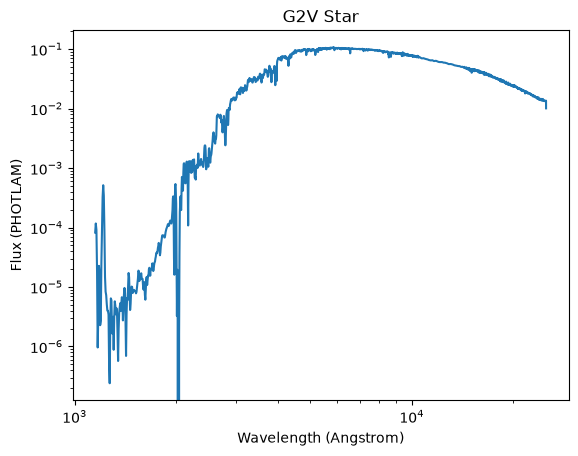

<Figure size 640x480 with 0 Axes>

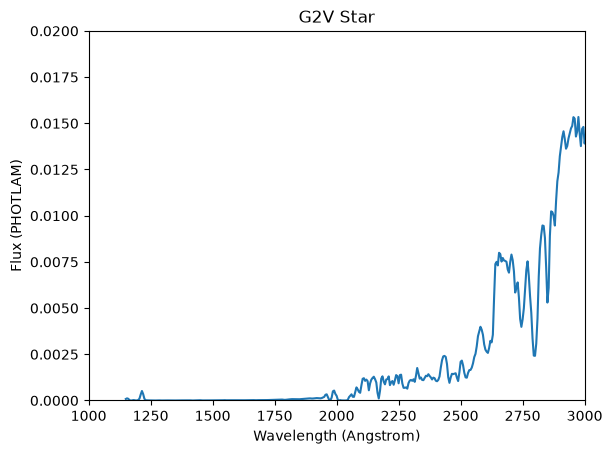

In [4]:
my_source.set_sed(name,10,0,0,bandpass='johnson,v')

# First plot, look at the full spectrum
my_source.sed.plot()
plt.yscale('log')
plt.xscale('log')
plt.title(name)

# Second plot, look at just the UV region
plt.figure()
my_source.sed.plot()
plt.title(name)
plt.xlim(1000,3000)
plt.ylim(0,0.02)

This template of a solar type star is likely excellent in many scientific use cases; however, the UV portion pretty much goes to zero flux. The spectral resolution appears relatively low, and there are no chromospheric emission lines. For a science case interested in high spectral resolution in the UV, a better SED source might be an **observation** of a very bright solar-type star.

## 3.0  Obtain and load an external source into the existing templates.  

In this sub-example, we will acquire data from the Hubble Spectroscopic Legacy Archive to obtain a high-resolution spectrum of bright solar-like star observed by HST. There are a few places where one might browse to see what has been observed, including
1. HSLA's [Tier 1 and Tier 2 direct query links](https://archive.stsci.edu/missions-and-data/hst/hsla/example-searches.html#h2-a4afc12e-b45e-4cf3-bd23-9078452dcf46)
2. [ULLYSES](https://ullyses.stsci.edu) target lists
3. [CALSPEC](https://www.stsci.edu/hst/instrumentation/reference-data-for-calibration-and-tools/astronomical-catalogs/calspec) standard stars
4. The HST STIS Advanced Spectral Library ([ASTRAL](https://archive.stsci.edu/prepds/astral/))

From ASTRAL, we see that alpha Cen A (a G2 V stars with V = 0.02) was observed with STIS high resolution.

Following the example in the  [HSLA Notebook](https://spacetelescope.github.io/hst_notebooks/notebooks/HSLA/Intro/Intro.html#hsla_download) we will download the full spectral range available for this object.

But be aware that when querying by a target name, there is different behavior if you pass the name to the "target_name" keyword (which only does an exact name match) versus passing it to "objectname" (which will resolve the target and query all known aliases).


In [5]:
# Create and define the default path for storing files
outdir = './hsla_default_products'
if not os.path.exists(outdir):
    os.makedirs(outdir)
output = Path(outdir)

In [6]:
target = 'alpha Cen A'  

'''
Be careful. If you use "target_name = target", it will only search on that exact target name
You must use "objectname = target" to do a name resolved query search.
'''

# Conduct the query
obs = Observations.get_product_list(
     Observations.query_criteria(
        provenance_name='HSLA',
        objectname=target  
    )
)

In [7]:
# Look at the list of available  science products.
obs[obs['productType'] == 'SCIENCE']   


obsID,obs_collection,dataproduct_type,obs_id,description,type,dataURI,productType,productGroupDescription,productSubGroupDescription,productDocumentationURL,project,prvversion,proposal_id,productFilename,size,parent_obsid,dataRights,calib_level,filters
str9,str3,str8,str27,str87,str1,str89,str9,str28,str5,str1,str4,str14,str5,str44,int64,str9,str6,int64,str24
349727704,HST,spectrum,hst_hsla_hd128621--6708,HSLA coadded and abutted spectrum for multiple gratings,S,mast:HST/product/hsla/hst_hd128621--6708/hst_hd128621--6708_aspec.fits,SCIENCE,Minimum Recommended Products,ASPEC,--,HSLA,HSLA Cal 1.2.5,17405,hst_hd128621--6708_aspec.fits,627840,349727704,PUBLIC,3,E140M
349727704,HST,spectrum,hst_hsla_hd128621--6708,HSLA coadded spectrum for a singular grating and/or COS lifetime position,S,mast:HST/product/hsla/hst_hd128621--6708/hst_stis_hd128621--6708_e140m_cspec.fits,SCIENCE,Minimum Recommended Products,CSPEC,--,HSLA,HSLA Cal 1.2.5,17405,hst_stis_hd128621--6708_e140m_cspec.fits,627840,349727704,PUBLIC,3,E140M
349727745,HST,spectrum,hst_hsla_hd128620--6709,HSLA coadded and abutted spectrum for multiple gratings,S,mast:HST/product/hsla/hst_hd128620--6709/hst_hd128620--6709_aspec.fits,SCIENCE,Minimum Recommended Products,ASPEC,--,HSLA,HSLA Cal 1.2.5,MULTI,hst_hd128620--6709_aspec.fits,3476160,349727745,PUBLIC,3,E140H;E140M;E230H
349727745,HST,spectrum,hst_hsla_hd128620--6709,HSLA coadded spectrum for a singular grating and/or COS lifetime position,S,mast:HST/product/hsla/hst_hd128620--6709/hst_stis_hd128620--6709_e140h_cspec.fits,SCIENCE,Minimum Recommended Products,CSPEC,--,HSLA,HSLA Cal 1.2.5,MULTI,hst_stis_hd128620--6709_e140h_cspec.fits,1120320,349727745,PUBLIC,3,E140H;E140M;E230H
349727745,HST,spectrum,hst_hsla_hd128620--6709,HSLA coadded spectrum for a singular grating and/or COS lifetime position,S,mast:HST/product/hsla/hst_hd128620--6709/hst_stis_hd128620--6709_e140m_cspec.fits,SCIENCE,Minimum Recommended Products,CSPEC,--,HSLA,HSLA Cal 1.2.5,MULTI,hst_stis_hd128620--6709_e140m_cspec.fits,627840,349727745,PUBLIC,3,E140H;E140M;E230H
349727745,HST,spectrum,hst_hsla_hd128620--6709,HSLA coadded spectrum for a singular grating and/or COS lifetime position,S,mast:HST/product/hsla/hst_hd128620--6709/hst_stis_hd128620--6709_e230h_cspec.fits,SCIENCE,Minimum Recommended Products,CSPEC,--,HSLA,HSLA Cal 1.2.5,MULTI,hst_stis_hd128620--6709_e230h_cspec.fits,2252160,349727745,PUBLIC,3,E140H;E140M;E230H
349727748,HST,spectrum,hst_hsla_hd128620--6738,HSLA coadded and abutted spectrum for multiple gratings,S,mast:HST/product/hsla/hst_hd128620--6738/hst_hd128620--6738_aspec.fits,SCIENCE,Minimum Recommended Products,ASPEC,--,HSLA,HSLA Cal 1.2.5,MULTI,hst_hd128620--6738_aspec.fits,1097280,349727748,PUBLIC,3,E140M;E230H;G230MB
349727748,HST,spectrum,hst_hsla_hd128620--6738,HSLA coadded spectrum for a singular grating and/or COS lifetime position,S,mast:HST/product/hsla/hst_hd128620--6738/hst_stis_hd128620--6738_e140m_cspec.fits,SCIENCE,Minimum Recommended Products,CSPEC,--,HSLA,HSLA Cal 1.2.5,MULTI,hst_stis_hd128620--6738_e140m_cspec.fits,633600,349727748,PUBLIC,3,E140M;E230H;G230MB
349727748,HST,spectrum,hst_hsla_hd128620--6738,HSLA coadded spectrum for a singular grating and/or COS lifetime position,S,mast:HST/product/hsla/hst_hd128620--6738/hst_stis_hd128620--6738_e230h_cspec.fits,SCIENCE,Minimum Recommended Products,CSPEC,--,HSLA,HSLA Cal 1.2.5,MULTI,hst_stis_hd128620--6738_e230h_cspec.fits,472320,349727748,PUBLIC,3,E140M;E230H;G230MB


In [8]:
# It looks like our query caught both alpha Cen A (HD 128620) and alpha Cen B (HD 128621).
# requery looking only for HD128620 without resolving the target_name
obs2 = Observations.get_product_list(
     Observations.query_criteria(
        provenance_name='HSLA',
        target_name="HD128620"  
    )
)

# Look for only the abutted spectra, and see what is available
abutted = obs2[(obs2['productType'] == 'SCIENCE') & (obs2['productSubGroupDescription'] == 'ASPEC')]
abutted['productFilename','filters']

productFilename,filters
str41,str18
hst_hd128620--6709_aspec.fits,E140H;E140M;E230H
hst_hd128620--6738_aspec.fits,E140M;E230H;G230MB
hst_hd128620--6739_aspec.fits,E140M


In [9]:
# the first run in the abutted table will give us the broadest and highest resolution data, so let's use that one
res_table = Observations.download_products(
    abutted[abutted['productType'] == 'SCIENCE'][0],
    download_dir=str(output)
)
res_table

INFO: Found cached file hsla_default_products/mastDownload/HST/hst_hsla_hd128620--6709/hst_hd128620--6709_aspec.fits with expected size 3476160. [astroquery.query]


Local Path,Status,Message,URL
str92,str8,object,object
hsla_default_products/mastDownload/HST/hst_hsla_hd128620--6709/hst_hd128620--6709_aspec.fits,COMPLETE,None,None


### 3.1 Load and inspect the downloaded spectrum
Compare the newly downloaded alpha Cen A spectrum with the solar template

In [10]:
hsla_data = fits.getdata(res_table['Local Path'][0])[0]


(1000.0, 3000.0)

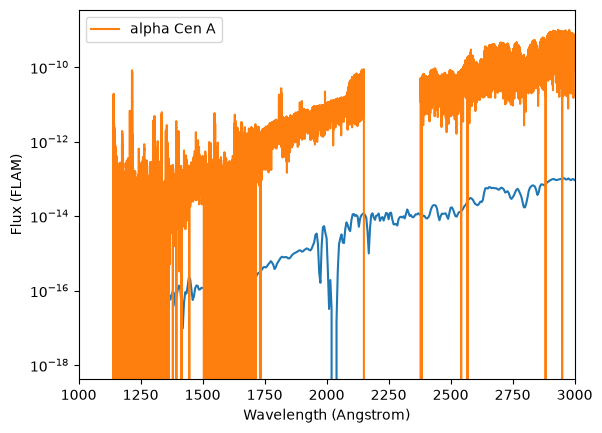

In [11]:
my_source.sed.plot(flux_unit='flam') # plot the G2V template
plt.plot(hsla_data['WAVELENGTH'], hsla_data['FLUX'],label=target) # plot the newly downloaded spectrum
plt.yscale('log')
plt.legend()
plt.xlim(1000,3000)

### 3.2 Add user spectrum as a new possible template.
This alpha Cen A spectrum should make a good high spectral resultion template, though the user should be aware of gaps in the spectral overage (e.g., around 2250 Angstroms).

In [12]:
my_spectrum = synphot.spectrum.SourceSpectrum(synphot.models.Empirical1D, points= hsla_data['WAVELENGTH'], 
                                              lookup_table= hsla_data['FLUX']*synphot.units.FLAM,keep_neg=False)

syn_spectra_library[target] = my_spectrum


  points: [1141.2463 1141.2532 1141.26   ... 1712.1571 1731.3961 1733.0673]
  lookup_table: [-0.99849012 -0.88767384 -1.13760885 ... -0.00274646 -0.00996415
 -0.00521662] [synphot.models]


In [13]:
#The new spectrum is now selectable as an option in the "my_source" object
my_source.list_templates()

dict_keys(['Classical T-Tauri Star', 'M1 Dwarf', 'M Dwarf', 'G Dwarf', 'O2V-like TLUSTY model (Teff=50000K, logg=4.0, Z=0.5 Zsun)', 'O4V-like TLUSTY model (Teff=42500K, logg=4.0, Z=0.2 Zsun)', 'O5V-like TLUSTY model (Teff=40000K, logg=4.0, Z=0.2 Zsun)', 'O5V Star', 'G2V Star', 'B5V Star', 'M2V Star', 'G191B2B (WD)', 'GD71 (WD)', 'GD153 (WD)', '10 Myr Starburst', 'QSO', 'Seyfert 1', 'Seyfert 2', 'Liner', 'Orion Nebula', 'Starburst, No Dust', 'Starburst, E(B-V) = 0.6', 'Elliptical Galaxy', 'Sbc Galaxy', 'NGC 1068', 'Galaxy with f_esc, HI=1, HeI=1', 'Galaxy with f_esc, HI=0.001, HeI=1', 'Flat (AB)', 'Flat in F_lambda', 'Blackbody (5000K)', 'Blackbody (100,000K)', 'alpha Cen A'])


### 3.3 Define normalization
In order to use this spectrum, we will need to able to normalize it within one of the available bandpasses. It covers the Gaia NUV bandpass, but the spectrum itself does not fully cover it (there is a gap at 2250 A). But that's ok. We can figure what the effective NUV magnitude is for this spectrum by normalizing it an arbitrary magnitude (we'll use zero for simplicity) and comparing the flux at a reference wavelength to the flux in the un-normalized spectrum

In [14]:
# now we need to get the normalization factors
# First, normalize to 0 magnitude in galex, NUV. Then compare to the actual flux.
# calculate what the NUV mag must be
my_source.set_sed(target,0,0,0,bandpass='galex,nuv')
ref_wave = 2750.

nuv_flux_0_mag = my_source.sed(ref_wave)
nuv_flux_unknown_mag = my_spectrum.model(ref_wave)

alpha_CenA_NUV = -2.5*np.log10(nuv_flux_unknown_mag/nuv_flux_0_mag.value)
print(alpha_CenA_NUV)

# Since alpha Cen A has V = 0.01, NUV - V = 6.59
# The NUV-V will let you normalize to solar-type stars with known V but unknown NUV magnitudes if needed
nuv_minus_v = alpha_CenA_NUV-0.01
print(nuv_minus_v)

6.596776662500544
6.586776662500545


Text(0.5, 1.0, 'Unnormalized alpha Cen A spectrum')

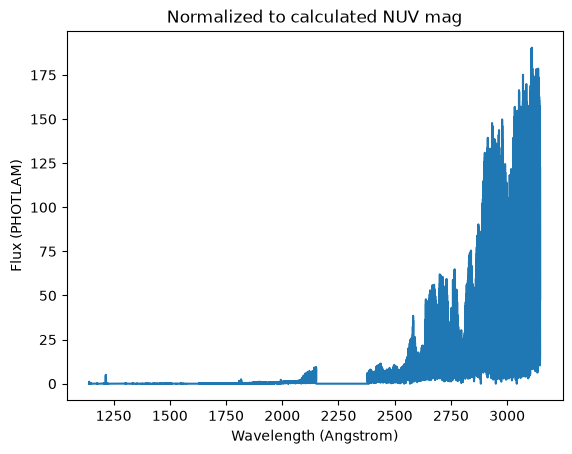

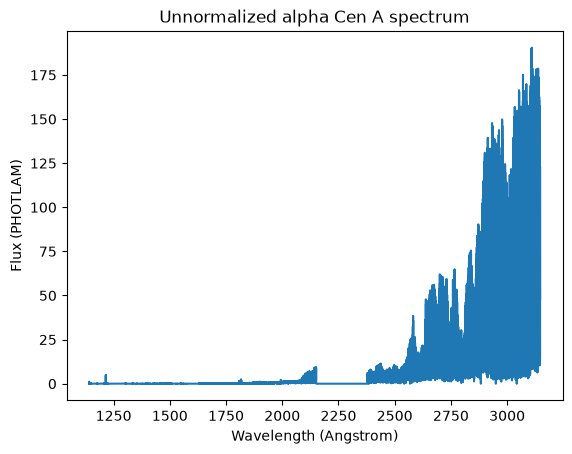

In [15]:
# Double check we got that right by plotting the SED normalized to the alpha_CenA_NUV mag and the original unnormalized
my_source.set_sed(target,alpha_CenA_NUV,0,0,bandpass='galex,nuv',force=True)

my_source.sed.plot()
plt.title('Normalized to calculated NUV mag')
my_spectrum.plot()
plt.title(f'Unnormalized {target} spectrum')

# These plots match!!

## 4.0 Exploring a Science Case
One use case is measuring r-process abundances in the UV at high spectral resolution and high S/N. We'll use the [Habitable WOrlds Observatory: The Nature of the Astrophysical r-Process](https://arxiv.org/pdf/2507.03180) paper for guidance.

According to that paper, NUV observations (down to ~2000 Angtroms) using STIS have been accomplished for V as faint as 9. New discovery space can be opened for wavelengths shorter than 2000 Angstroms and for the 2000-3000 Angstroms region for fainter stars.

We'll pull some wavelengths from Table 1 and pick some representative V-magnitudes, including the faintest star with good r-process measurements from STIS, and the peak of the magnitude distribution of r-processed ehanced stars from Figure 2.

* Case 1: V = 9, approximate faint limit for HST/STIS
* Case 2: V = 12.5, median V mag of known r-process enhanced stars

In [16]:
# define some goals for the science cases
goal_snr = 30.
v_mags = np.array([9,12.5])
associ_impact = ['NUV STIS limit','Median r-process enhanced']
key_waves = np.array([1540,1586,1606,1791, 1875,1942,2020,2185,2282,2615,2752,3039])  # Table 1 of referenced arXiv paper

## 5.0 Define the observation 
Assuming you do not yet know exactly what capabilities are available, this next set of code will walk you through finding the appropriate instrument setup and defining the observation to test for feasibility. These stepas are:

1. Instantiate the HWO telescope object and load the paramters from EAC5
2. Find and load the appropriate instrument configuration. For this case, we want the FUV_PSS.Echelle, which is the only high spectral resolution channel currently being modeled
3. Define an exposure. For this example, we'll set the desired S/N and request the needed exposure time and vice versa

In [17]:
#Instantiate the observatory using syotools.models.Telescope
hwo_ex1 = Telescope()
hwo_ex1.set_from_hwome('EAC5') 

### 5.1 Explore options if needed

In [18]:
# List out the available instruments
for k in hwo_ex1.instruments.keys():
    print(k)

HRI_A.HRI_A_VIS_Imager
HRI_S.HRI_S_NIR_Imager
HRI_S.HRI_S_NIR_Spectrograph
HRI_S.HRI_S_UVIS_Imager
HRI_S.HRI_S_UVIS_Spectrograph
UV_IFU.UV_IFU_Group1_IFS
UV_IFU.UV_IFU_Group2_IFS
UV_IFU.UV_IFU_Group3_IFS
UV_IFU.UV_IFU_Group4_IFS
UV_MOS.FUV_IMG_Imager
UV_MOS.FUV_MOS_MOS
UV_MOS.FUV_MOS_L_MOS
UV_MOS.NUV_MOS_MOS
UVI_PSS.FUV_PSS_Spectrograph
UVI_PSS.NUV_PSS_Spectrograph


In [19]:
# Once you select an instrument, you can then see what channels, or "bands"  are available
my_instru = hwo_ex1.instruments['UVI_PSS.NUV_PSS_Spectrograph']
print(my_instru.n_bands)
print(my_instru.bandnames)
print(my_instru.configuration['band']['NUV_PSS.Echelle_NUV']['resolution'])

1
['NUV_PSS.Echelle_NUV']
120250.25634263085


In [20]:
my_instru = hwo_ex1.instruments['UVI_PSS.FUV_PSS_Spectrograph']
print(my_instru.n_bands)
print(my_instru.bandnames)
print(my_instru.configuration['band']['FUV_PSS.Echelle']['resolution'])

1
['FUV_PSS.Echelle']
114286.0


In [21]:
# The highest resolution mode is on the UVI_PSS.FUV_PSS_Spectrograph and UVI_PSS.NUV_PSS_Spectrograph instruments, but there 
# are other more moderate resolution options on the UV_MOS.NUV_MOS_MOS and UV_MOS.FUV_MOS_MOS channels instruments. This code
# will loop through the user input list of instrument choices and show what all the mode/resolution/wavelength range options are

# List of instruments to see more info about
ins_choices = ['UVI_PSS.FUV_PSS_Spectrograph','UVI_PSS.NUV_PSS_Spectrograph','UV_MOS.FUV_MOS_MOS','UV_MOS.NUV_MOS_MOS']

# Loop through the different instruments and print out the band options, with highest and lowest wavebin and spectral resolution
for choice in ins_choices:
    my_instru = hwo_ex1.instruments[choice]
    print(f'\n Options for {choice} instrument')
    for one_band in my_instru.bandnames:
        band_info = my_instru.configuration['band'][one_band]
        print('  {}  R={:.0f} l={:.0f}-{:.0f}'.format(one_band, band_info['resolution'],\
                                                      band_info['wave_min'].value,band_info['wave_max']))



 Options for UVI_PSS.FUV_PSS_Spectrograph instrument
  FUV_PSS.Echelle  R=114286 l=1161-1858 Angstrom

 Options for UVI_PSS.NUV_PSS_Spectrograph instrument
  NUV_PSS.Echelle_NUV  R=120250 l=2125-3949 Angstrom

 Options for UV_MOS.FUV_MOS_MOS instrument
  FUV_MOS.G120M  R=30000 l=1094-1540 Angstrom
  FUV_MOS.G150M  R=30000 l=1149-1818 Angstrom
  FUV_MOS.G180M  R=30000 l=1434-2171 Angstrom

 Options for UV_MOS.NUV_MOS_MOS instrument
  NUV_MOS.G300M  R=20000 l=2152-4275 Angstrom
  NUV_MOS.G650LL  R=500 l=3939-8715 Angstrom
  NUV_MOS.G700L  R=15000 l=4121-9301 Angstrom


### 5.2  Make the instrument and band selections - Very High resolution NUV observations
Now that we have seen what some of the options are, we can select a configuration to use for creating the exposures.

We'll start with the highest resolution option we have available to model. For the coolest stars, FUV may be challenging so we will test out the NUV.

In [22]:
# Edit these two options to select the instrument and band to work with
ins_choice = 'UVI_PSS.NUV_PSS_Spectrograph'
band_choice =  'NUV_PSS.Echelle_NUV'

In [23]:
# Use the choices above to define the instrument setup
ins = hwo_ex1.instruments[ins_choice]
resolution = ins.configuration['band'][band_choice]['resolution']  # for plot label purposes
ins.band=band_choice

In [24]:
# Choose the units you want to plot. Set the target name you want to use from the list of available templates
t_unit='hr'

# The plotting code below is set up to loop through the representative v-magnitudes defined by the science case but also be
# flexible enough but be able to normalize in different bands with different templates. 
# E.g., if you decide to use the generic "G2V Star", you could normalize to bandpass='johnson,v' and set  "bandpass_minus_v = 0"

# For this example, use the user-inputed spectrum
name = 'alpha Cen A'
bandpass = 'galex,nuv'
band_minus_v = nuv_minus_v

### Plot needed exposure time for fixed S/N
In the following plot, syotools is used to calculate the exposure time needed to attain a fixed S/N defined by "goal_snr".

The time is calcaulted at each wavelength, so the result appears as an inverted spectrum (absoprtion features require longer exposure times). 

Vertical lines mark the location of "key" spectral features from Table 1 of [Habitable WOrlds Observatory: The Nature of the Astrophysical r-Process](https://arxiv.org/pdf/2507.03180)

/Users/jcarlberg/miniconda3/envs/hwotools/lib/python3.13/site-packages/astropy/units/quantity.py:676: RuntimeWarning: divide by zero encountered in divide
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)
/Users/jcarlberg/miniconda3/envs/hwotools/lib/python3.13/site-packages/astropy/units/quantity.py:676: RuntimeWarning: invalid value encountered in divide
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)
/Users/jcarlberg/miniconda3/envs/hwotools/lib/python3.13/site-packages/astropy/units/quantity.py:676: RuntimeWarning: divide by zero encountered in divide
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)
/Users/jcarlberg/miniconda3/envs/hwotools/lib/python3.13/site-packages/astropy/units/quantity.py:676: RuntimeWarning: invalid value encountered in divide
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


(0.1, 1000000.0)

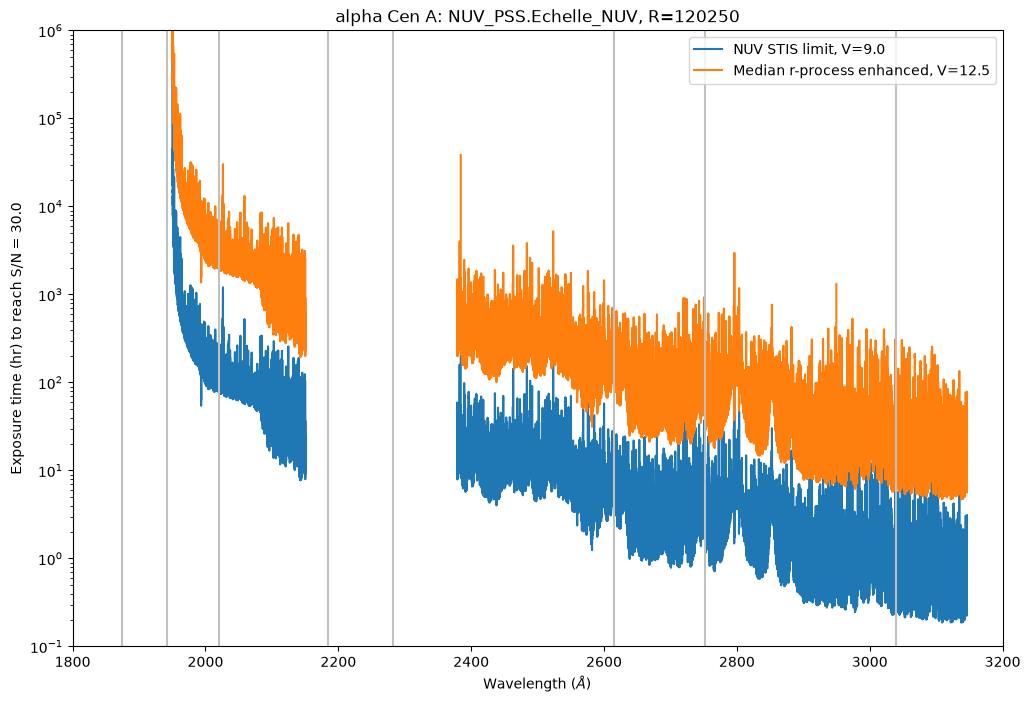

In [25]:
f=plt.figure(figsize=(12,8))
for v, impact in zip (v_mags, associ_impact):
    my_source.set_sed(name,v+band_minus_v,0,0,bandpass=bandpass)

    # Create and add the exposure
    exposure = ins.create_exposure(source = my_source)
    exposure.instrument.band = band_choice  #I can't verify this is doing what I want!
    exposure.snr = goal_snr
    exposure.unknown = "exptime"
    exp_time  = exposure.recover('exptime')
    plt.plot(exposure.wave[0],exp_time[0].to(t_unit),label=f'{impact}, V={v}')
plt.legend()
plt.yscale('log')
plt.ylabel(f'Exposure time ({t_unit}) to reach S/N = {goal_snr}')
plt.xlabel(r'Wavelength ($\AA$)')

for a_wave in key_waves:
    plt.axvline(a_wave,color='silver')
plt.title('{}: {}, R={:.0f}'.format(my_source.name, band_choice, resolution))
plt.xlim(1800,3200)
plt.ylim(0.1,1e6) 

### Plot S/N attained at fixed exposure time
In this example, we use syotools to calculate the S/N achieved in a fix exposure time (5 hours in this example). To showcase the high resolution, we zoom in on one of the key lines in [Habitable WOrlds Observatory: The Nature of the Astrophysical r-Process](https://arxiv.org/pdf/2507.03180). A high precision line center is needed, which can be obtained from NIST. Example: [NIST result for Lu II](https://physics.nist.gov/cgi-bin/ASD/lines1.pl?spectra=Lu+II&output_type=0&low_w=2614&upp_w=2616&unit=0&submit=Retrieve+Data&de=0&plot_out=0&I_scale_type=1&format=0&line_out=0&en_unit=0&output=0&bibrefs=1&page_size=15&show_obs_wl=1&show_calc_wl=1&unc_out=1&order_out=0&max_low_enrg=&show_av=2&max_upp_enrg=&tsb_value=0&min_str=&A_out=0&intens_out=on&max_str=&allowed_out=1&forbid_out=1&min_accur=&min_intens=&conf_out=on&term_out=on&enrg_out=on&J_out=on
).

The STIS spectrum used for the spectral template is in vacuum wavelengths ([STIS IHB 1.2.1](https://hst-docs.stsci.edu/stisihb/chapter-1-introduction/1-2-introduction-to-the-handbook#id-1.2IntroductiontotheHandbook-Section1.2.11.2.1DocumentConventions)), so the NIST result must be converted from air to vacuum for a proper comparison.

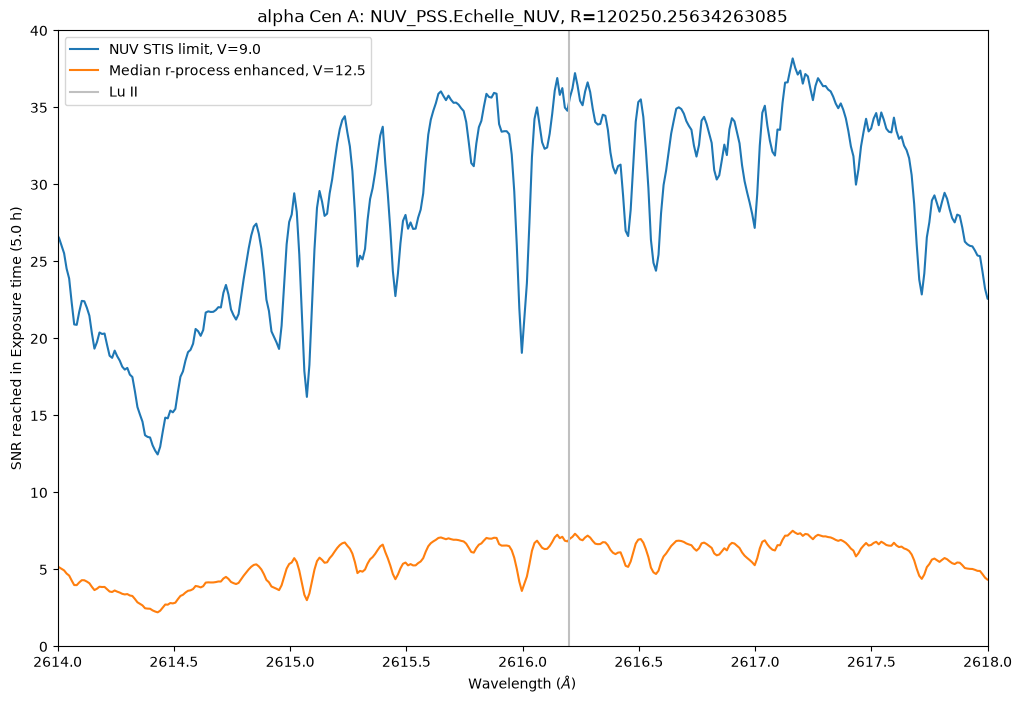

In [26]:
# reverse the problem, and see what the S/N is obtained in an some set exposure time
# This example zooms in around a Lu II line (2615.42 Angstroms in air (from NIST) is roughly 2616.2 in vacuum)
# 
goal_exptime= 5*u.hr
lu_ii_air = 2615.42 * u.Angstrom
lu_ii_vac = air_to_vac(lu_ii_air)

f=plt.figure(figsize=(12,8))
for v, impact in zip (v_mags, associ_impact):
    my_source.set_sed(name,v+band_minus_v,0,0,bandpass=bandpass)

    # Create and add the exposure
    exposure = ins.create_exposure(source=my_source)
    exposure.instrument.band = band_choice
    exposure.exptime = goal_exptime
    exposure.unknown = "snr"
    snr  = exposure.recover('snr')
    plt.plot(exposure.wave[0],snr[0],label=f'{impact}, V={v}')
#plt.yscale('log')
plt.ylabel(f'SNR reached in Exposure time ({goal_exptime})')
plt.xlabel(r'Wavelength ($\AA$)')

plt.axvline(2616.2,color='silver',label='Lu II')
    
plt.title(f'{my_source.name}: {band_choice}, R={resolution}')
plt.ylim(0,40)
plt.xlim(2614,2618)
plt.legend()


### 5.3  Exploring alternate solutions FUV/NUV
While achieving a reasonably high S/N for lines in the long wavelength end of the NUV bandpass at very high resolution is feasible (e.g., the Lu II example above), the required exposure times get prohibitively expensive at shorter wavelengths. Nevertheless, the science will  cover new ground even at lower resolutions (especially for relatively unblended lines) when pushing to shorter wavelengths. The next example shows the results using a different high resolution set-ups.


In [27]:
ins_choice = 'UV_MOS.FUV_MOS_MOS'
band_choice =  'FUV_MOS.G180M'

ins = hwo_ex1.instruments[ins_choice]
resolution = ins.configuration['band'][band_choice]['resolution']  # for plot label purposes
ins.band=band_choice

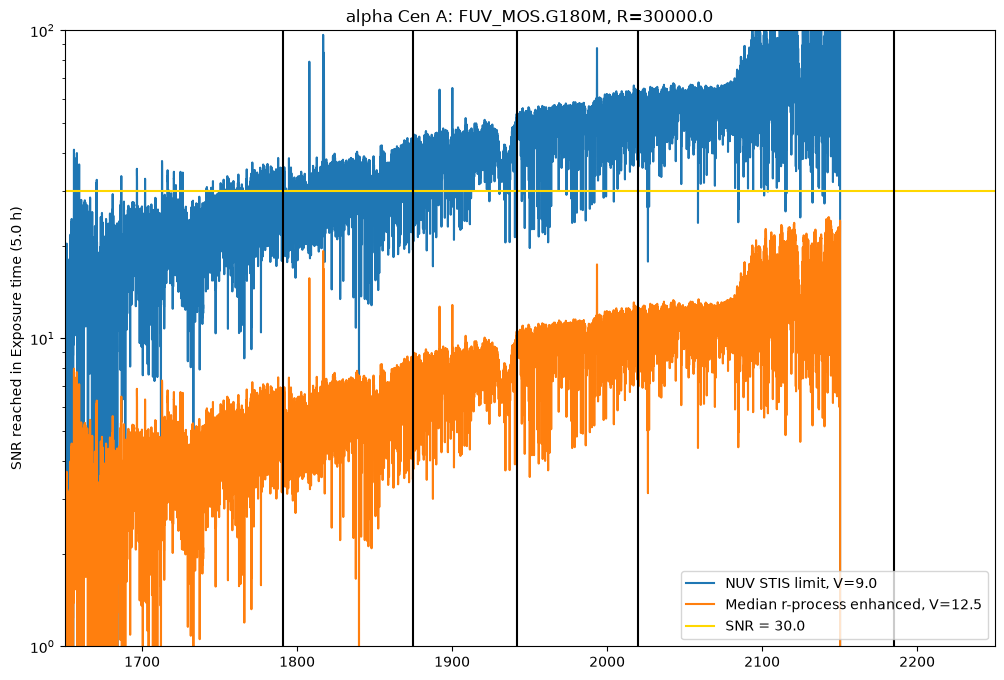

In [28]:
# What is the achievable S/N in 5 hours at lower spectral resoultion in the FUV?

goal_exptime= 5*u.hr

f=plt.figure(figsize=(12,8))
for v, impact in zip (v_mags, associ_impact):
    my_source.set_sed(name,v+band_minus_v,0,0,bandpass=bandpass)

    # Create and add the exposure
    exposure = ins.create_exposure(source=my_source)
    exposure.instrument.band = band_choice
    exposure.exptime = goal_exptime
    exposure.unknown = "snr"
    snr  = exposure.recover('snr')
    plt.plot(exposure.wave[0],snr[0],label=f'{impact}, V={v}')
plt.axhline(goal_snr,color='gold',label=f'SNR = {goal_snr}')
plt.ylabel(f'SNR reached in Exposure time ({goal_exptime})')
plt.legend()

for a_wave in key_waves:
    plt.axvline(a_wave,color='black')
    
plt.xlim(1650,2250)
plt.title(f'{my_source.name}: {band_choice}, R={resolution}')
plt.ylim(1,100)
plt.yscale('log')